# Metamodel case generation

Workflow:

1. Load **goals** from `Samoa.json` → `simulations.goals_file`.
2. Generate **Latin Hypercube** cases per goal (`tp`, `wd`, `ds`, `zs`).
3. Build SnapWave case directories from `templates-metamodel`.
4. Run cases (optional) and postprocess to per-goal NetCDF files.

Paths and bounds come from `Samoa.json` → `simulations`.

In [1]:
from utils.config import PATHS, SIMULATIONS, goals_for_snapwave, load_goals, resolve
from utils.simulation import lhs_cases as sim
from utils.simulation.snapwave_wrappers import SnapWaveMetaModelWrapper

## Configuration

In [2]:
templates_dir = resolve(SIMULATIONS["metamodel_templates"])
cases_dir = resolve(SIMULATIONS["metamodel_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])

print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"samples   : {SIMULATIONS['num_samples_per_goal']} per goal")

goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Goals/Samoa_Goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/templates-metamodel
cases     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Metamodel
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GRID/Samoa_mesh.nc
samples   : 5 per goal


## LHS cases

In [3]:
raw_goals = load_goals()

cases_df = sim.generate_cases(raw_goals)
cases_df["goal"] = cases_df["goal"].astype(int)
cases_df.head()

,goal,tp,dir,spr,wl
0,1,2.366899,204.042818,34.931395,-3.428109
1,1,8.526872,319.482448,37.716217,2.927121
2,1,13.461138,291.881100,11.969085,-0.053401
3,1,5.676751,348.484577,7.131886,1.465103
4,1,11.824683,183.365799,25.609594,-1.067239


In [4]:
# Quick LHS preview (full diagnostic map is in the next section)
cases_df.groupby("goal")[["tp", "dir", "spr", "wl"]].describe()


tp                                                               \
     count      mean       std       min       25%       50%        75%   
goal                                                                      
1      5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
2      5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
3      5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
4      5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
5      5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
6      5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
7      5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
8      5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
9      5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
10     5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
11     5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
12     5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
13     5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
14     5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
15     5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   
16     5.0  8.371269  4.504718  2.366899  5.676751  8.526872  11.824683   

                  dir              ...        spr               wl            \
            max count        mean  ...        75%        max count      mean   
goal                               ...                                         
1     13.461138   5.0  269.451348  ...  34.931395  37.716217   5.0 -0.031305   
2     13.461138   5.0  186.239619  ...  34.931395  37.716217   5.0 -0.031305   
3     13.461138   5.0  159.287018  ...  34.931395  37.716217   5.0 -0.031305   
4     13.461138   5.0  168.145403  ...  34.931395  37.716217   5.0 -0.031305   
5     13.461138   5.0  165.663981  ...  34.931395  37.716217   5.0 -0.031305   
6     13.461138   5.0  165.663981  ...  34.931395  37.716217   5.0 -0.031305   
7     13.461138   5.0  175.653739  ...  34.931395  37.716217   5.0 -0.031305   
8     13.461138   5.0  153.327729  ...  34.931395  37.716217   5.0 -0.031305   
9     13.461138   5.0  132.167858  ...  34.931395  37.716217   5.0 -0.031305   
10    13.461138   5.0  159.229959  ...  34.931395  37.716217   5.0 -0.031305   
11    13.461138   5.0  193.623271  ...  34.931395  37.716217   5.0 -0.031305   
12    13.461138   5.0  179.213511  ...  34.931395  37.716217   5.0 -0.031305   
13    13.461138   5.0  187.040524  ...  34.931395  37.716217   5.0 -0.031305   
14    13.461138   5.0  208.056290  ...  34.931395  37.716217   5.0 -0.031305   
15    13.461138   5.0  189.182560  ...  34.931395  37.716217   5.0 -0.031305   
16    13.461138   5.0  230.409312  ...  34.931395  37.716217   5.0 -0.031305   

                                                                  
           std       min       25%       50%       75%       max  
goal                                                              
1     2.429169 -3.428109 -1.067239 -0.053401  1.465103  2.927121  
2     2.429169 -3.428109 -1.067239 -0.053401  1.465103  2.927121  
3     2.429169 -3.428109 -1.067239 -0.053401  1.465103  2.927121  
4     2.429169 -3.428109 -1.067239 -0.053401  1.465103  2.927121  
5     2.429169 -3.428109 -1.067239 -0.053401  1.465103  2.927121  
6     2.429169 -3.428109 -1.067239 -0.053401  1.465103  2.927121  
7     2.429169 -3.428109 -1.067239 -0.053401  1.465103  2.927121  
8     2.429169 -3.428109 -1.067239 -0.053401  1.465103  2.927121  
9     2.429169 -3.428109 -1.067239 -0.053401  1.465103  2.927121  
10    2.429169 -3.428109 -1.067239 -0.053401  1.465103  2.927121  
11    2.429169 -3.428109 -1.067239 -0.053401  1.465103  2.927121  
12    2.429169 -3.428109 -1.067239 -0.053401  1.465103  2.927121  
13    2.429169 -3.428109 -1.067239 -0.053401  1.465103  

## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + direction-range bars per goal; right side = text summary.
Review this before `build_cases()`.

In [5]:
wrapper = SnapWaveMetaModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    aoi_file=str(aoi_file),
    goals_config=goals_for_snapwave(raw_goals),
)
wrapper

2026-07-07 13:15:11,368 - SnapWaveMetaModelWrapper - WARNING - Parameter goal is not in the default_parameters
2026-07-07 13:15:11,368 - SnapWaveMetaModelWrapper - WARNING - Parameter tp is not in the default_parameters
2026-07-07 13:15:11,369 - SnapWaveMetaModelWrapper - WARNING - Parameter dir is not in the default_parameters
2026-07-07 13:15:11,370 - SnapWaveMetaModelWrapper - WARNING - Parameter spr is not in the default_parameters
2026-07-07 13:15:11,370 - SnapWaveMetaModelWrapper - WARNING - Parameter wl is not in the default_parameters


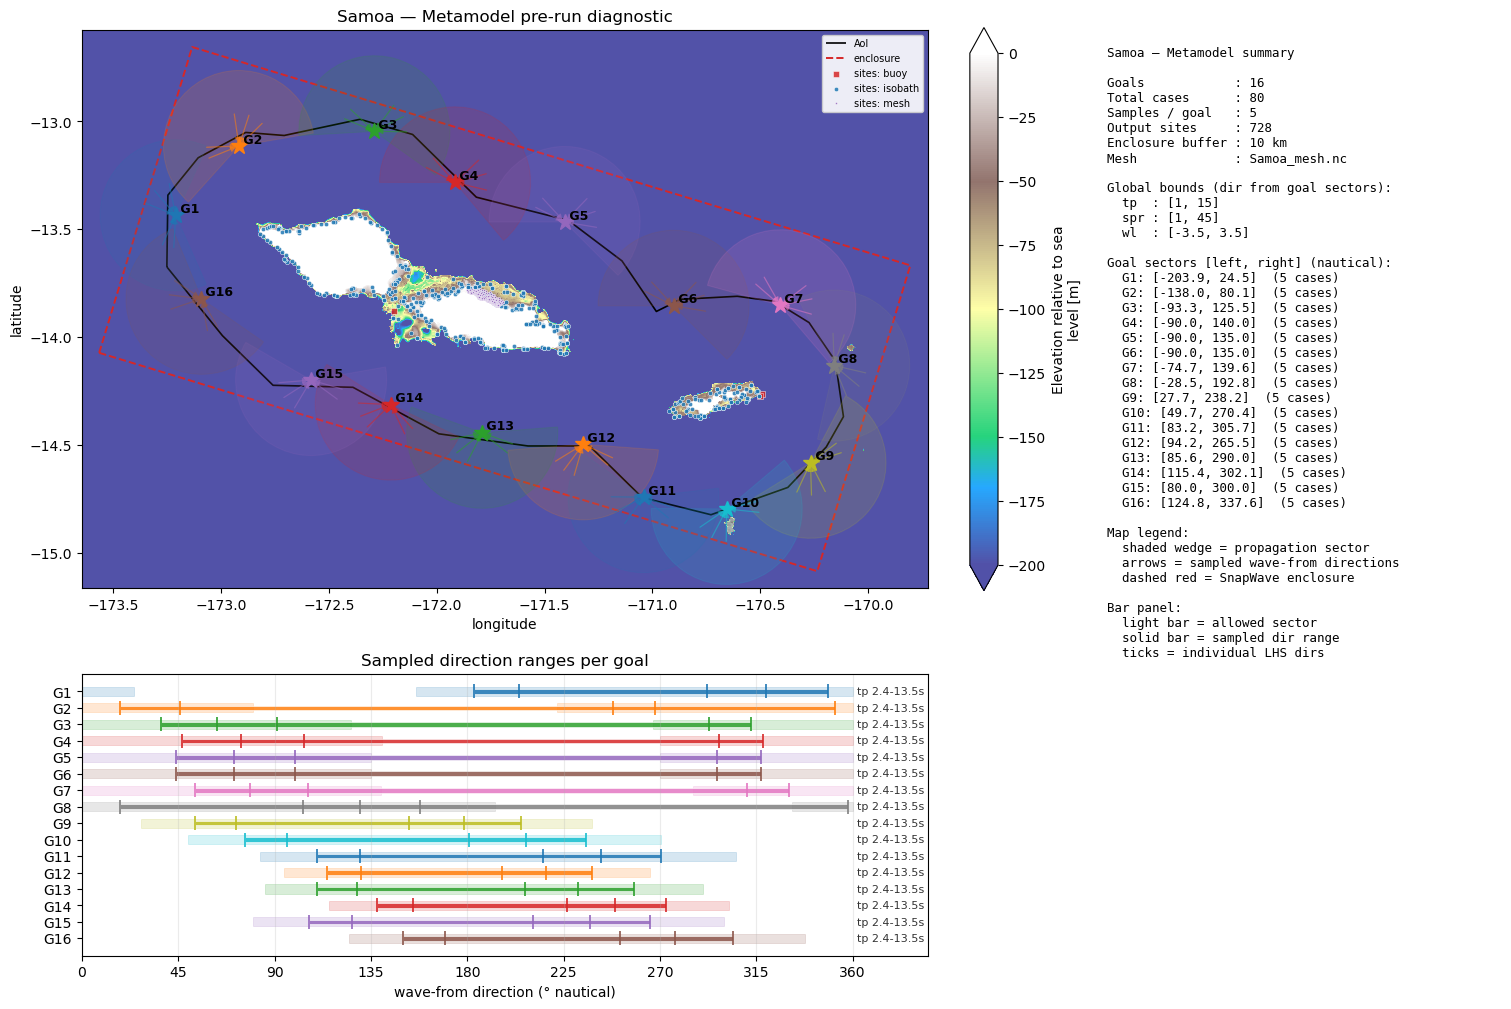

In [6]:
fig = wrapper.plot_configuration()
# fig.savefig("metamodel_setup_check.png", dpi=150, bbox_inches="tight")


## Build, run, postprocess

In [8]:
wrapper.build_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [10]:
wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [48]:
wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    5500
Name: count, dtype: int64

In [49]:
wrapper.postprocess_cases()

'Done'